# Neighbourhood profiling around cell types

Final Stage 1 objects → distance from each malignant cell to its nearest neighbour of each type, Nhood enrichment z-scores, and neighbour composition around selected cell types.

The analysis code is the same as in the original neighbourhood profiling notebook. This copy reads the final Stage 1 objects, keeps the cells behind each figure, and saves every figure and table to `OUTPUT_DIR`.

| Section | Figure |
|---|---|
| 1. Nearest-neighbour distances from malignant cells | Extended Data Fig. 6d, Fig. 4e (with repeated-measures ANOVA) |
| 2. Nhood enrichment | Extended Data Fig. 6e, Fig. 4f, Fig. 5d |
| 3. Neighbour composition | Fig. 4c, Fig. 5c |

In [1]:
import os, random, numpy as np
SEED = 23
os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
random.seed(SEED)
np.random.seed(SEED)

## Parameters

In [ ]:
# Folders and input files: set these before running (papermill parameters)
STAGE1_DIR = "/path/to/stage1_output"  # one subfolder per sample, with <sample>.h5ad
OUTPUT_DIR = "/path/to/stage2_output/neighbourhood_profiling"

In [2]:
FIGURE_DIR = os.path.join(OUTPUT_DIR, "figures")

radius = 50.0  # µm
sample_names = [
    "MH065_314", "MH074_314", "MH096_314", "MH097_314",
    "MH099_314", "MH104_314", "MH106_314", "MH107_314",
    "MH065_480", "MH074_480", "MH096_480", "MH097_480",
    "MH099_480", "MH104_480", "MH106_480", "MH107_480"
]

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
import squidpy as sq
import os
from collections import Counter, defaultdict
from scipy.spatial import cKDTree
from scipy.stats import shapiro, ttest_rel
from statsmodels.stats.anova import AnovaRM
import pingouin as pg

os.makedirs(FIGURE_DIR, exist_ok=True)


def save(name):
    plt.savefig(os.path.join(FIGURE_DIR, name), dpi=300, bbox_inches="tight")

~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/dask/dataframe/_pyarrow_compat.py:15: FutureWarning: Minimal version of pyarrow will soon be increased to 14.0.1. You are using 13.0.0. Please consider upgrading.
  warnings.warn(
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


## Load the final Stage 1 objects

Only the labels, coordinates and Nhood enrichment results are used.

In [4]:
def load_stage1(sample):
    full = sc.read_h5ad(os.path.join(STAGE1_DIR, sample, f"{sample}.h5ad"), backed="r")
    ad = sc.AnnData(obs=full.obs[["cell_class_threshold"]].copy())
    ad.obsm["spatial"] = np.asarray(full.obsm["spatial"]).copy()
    ad.uns["cell_class_threshold_nhood_enrichment"] = full.uns["cell_class_threshold_nhood_enrichment"]
    full.file.close()
    return ad


adata_list = [load_stage1(sample) for sample in sample_names]
adata_dict = dict(zip(sample_names, adata_list))

In [5]:
manual_colors = {
    'Acinar': '#ffb500',
    'Acinar_REG+': '#d4cd5c', #'#17becf', #
    'Adipocytes': '#0d0d0d', #‘black',
    'B cells':  '#ff7f0e',
    'CAFs_CXCL14':'#FFB0A7',
    'CAFs_MYO': '#FFE5A7', #'#c7c7c7',
    'CAFs_NRT': "#B4584D",
    "CD4 T cells":  '#7d87b9',
    "CD4 Tfh" : "#46487E",
    "CD4 Treg": '#536CC7',
    "CD8 T cells":'#023fa5',
    "CD8 TRM": "#0A295E",
    "DC1": "#888D07",
    "DC2": "#717417", 
    "Ductal": '#00846f',
    "Ductal MUC5B":'#8dd593',
    "Endocrine": '#809693',
    "Endothelial":'#d62728',
    "FDCs":"#DD51AD",
    "FRCs": "#00BFA0",
    "LECs": "#535A06",
    "TRCs": '#D8D18C',
    "Malignant cells": '#8c564b',
    "Mast": '#000035',
    "Migratory DCs": "#105354",
    "NK": "#00025E",
    "Neutrophils": '#b903aa',
    "Pericytes": '#d5eae7', #'#c5b0d5',
    "Plasma": '#9cded6',
    "SMCs": '#d5eae7', #'#c5b0d5',
    "Schwann": '#b79762',
    "TAMs_C1QC":'#c5b0d5',
    "TAMs_MHC": "#5E21E3",
    "TAMs_OLR1":'#e377c2',
    "TAMs_SPP1": '#17becf',
    "Unclassified": "#cccccc",
    "gdT": '#000035', 
    "pDCs":'#1b4400',
    "Tuft": '#9467bd',
    "IPMN": "#525068",
    "Ductal REG+": "#9aa880",
    "Neurons":"gold",
    "Other": '#cccccc'
    
}

## 1. Nearest-neighbour distances from malignant cells

For each malignant cell, the distance to the nearest cell of each other type within 50 µm.

In [6]:
all_results = []

for adata, sample_name in zip(adata_list, sample_names):
    coords = adata.obsm['spatial']
    cell_types = adata.obs['cell_class_threshold']
    cell_ids = adata.obs_names

    center_mask = (cell_types == "Malignant cells")
    center_coords = coords[center_mask.values]
    center_ids = cell_ids[center_mask.values]

    # Only build tree for non-malignant cells
    other_mask = ~center_mask
    other_coords = coords[other_mask.values]
    other_ids = cell_ids[other_mask.values]
    other_types = cell_types[other_mask.values].values

    # Build a cKDTree on non-malignant cells
    tree = cKDTree(other_coords)
    radius_um = radius

    for i, center_coord in enumerate(center_coords):
        center_id = center_ids[i]
        neighbor_idx = tree.query_ball_point(center_coord, r=radius_um)

        if not neighbor_idx:
            continue  # skip if no neighbors

        # Get neighbor types
        neighbor_types = other_types[neighbor_idx]
        neighbor_dists = np.linalg.norm(other_coords[neighbor_idx] - center_coord, axis=1)

        # Track minimum distance per target type
        dist_by_type = defaultdict(list)
        for t, d in zip(neighbor_types, neighbor_dists):
            dist_by_type[t].append(d)

        for t, dlist in dist_by_type.items():
            all_results.append({
                'Sample': sample_name,
                'Center_cell_ID': center_id,
                'Target_cell_type': t,
                'Min_Distance_um': min(dlist)
            })

# Compile into DataFrame
proximity_df = pd.DataFrame(all_results)

proximity_df.to_csv(os.path.join(OUTPUT_DIR, "Min-distance_Profiling50micrometers_Malignantcells.csv.gz"), index=False)
print(f"Malignant cells with neighbors: {proximity_df['Center_cell_ID'].nunique()}")
print(f"unique sample: {proximity_df['Sample'].nunique()}")

Malignant cells with neighbors: 433949
unique sample: 16


### Extended Data Fig. 6d: median distance per sample, all neighbour types

~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


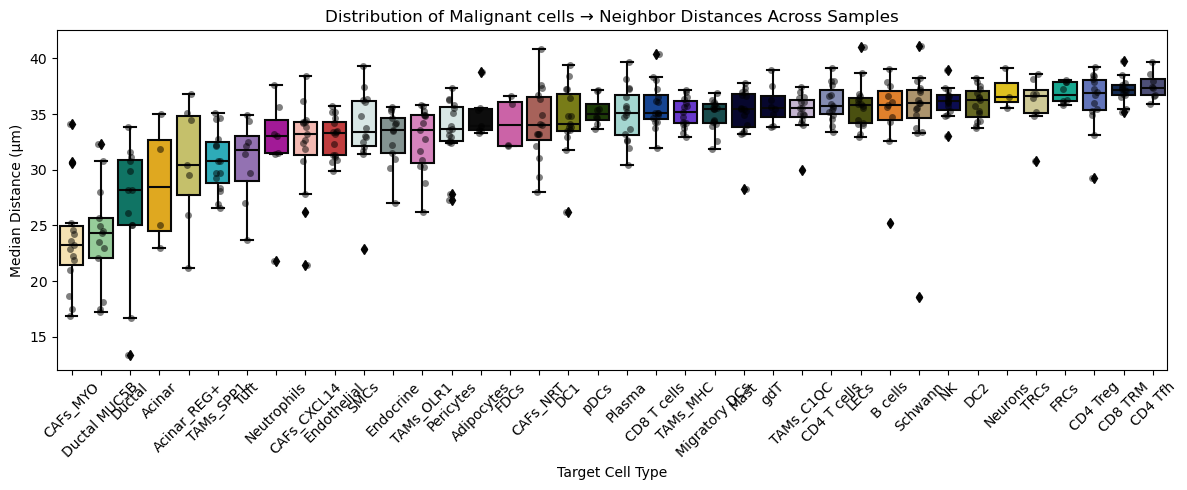

In [7]:
median_matrix = (
    proximity_df
    .groupby(["Sample", "Target_cell_type"])["Min_Distance_um"]
    .median()
    .unstack()
    .fillna(np.nan)
)

# Step 1: Melt for plotting
melted = (
    median_matrix
    .reset_index()
    .melt(id_vars="Sample", var_name="Target_cell_type", value_name="Median_Distance_um")
)

# Step 2: Compute global median for ordering
order = (
    melted.groupby("Target_cell_type")["Median_Distance_um"]
    .median()
    .sort_values()
    .index.tolist()
)
# Step 3: colors

# Exclude specific target cell types
exclude = ["Ductal REG+", "Unclassified", "IPMN"] #<<< less than 3 samples
melted = melted[~melted["Target_cell_type"].isin(exclude)]

# Also remove them from the order list
order = [cell_type for cell_type in order if cell_type not in exclude]

# Step 4: Plot with ordering and colors
plt.figure(figsize=(12, 5))
sns.boxplot(
    data=melted,
    x="Target_cell_type",
    y="Median_Distance_um",
    order=order,
    palette=manual_colors
)
sns.stripplot(
    data=melted,
    x="Target_cell_type",
    y="Median_Distance_um",
    order=order,
    color='black',
    alpha=0.5
)
plt.title("Distribution of Malignant cells → Neighbor Distances Across Samples")
plt.ylabel("Median Distance (µm)")
plt.xlabel("Target Cell Type")
plt.xticks(rotation=45)
plt.tight_layout()
save("EDFig6d_Persample_median_distant_PDAC_neighbours_all.pdf")
plt.show()

### Fig. 4e: median distance to CAF and TAM subtypes

In [8]:
focus_labels = ['CAFs_MYO', 'CAFs_NRT', 'CAFs_CXCL14','TAMs_SPP1',"TAMs_OLR1","TAMs_C1QC","TAMs_MHC"] #,"Schwann","Neurons"] #,"Ductal","Ductal MUC5B","CD8 T cells","CD8 TRM"]
# Filter DataFrame
focus_df = proximity_df[proximity_df['Target_cell_type'].isin(focus_labels)].copy()

~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


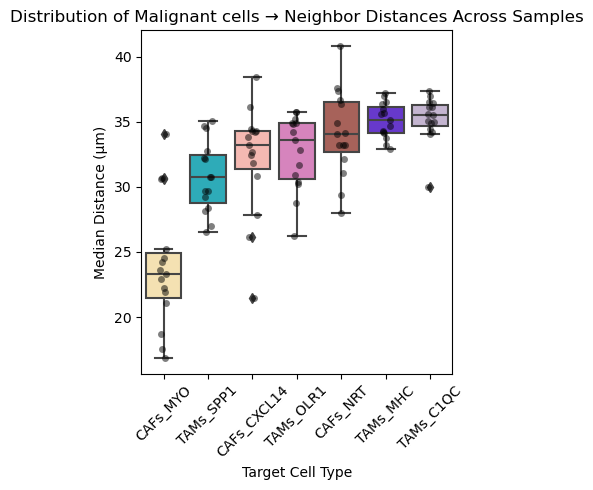

In [9]:
median_matrix = (
    focus_df
    .groupby(["Sample", "Target_cell_type"])["Min_Distance_um"]
    .median()
    .unstack()
    .fillna(np.nan)
)

# Step 1: Melt for plotting
melted = (
    median_matrix
    .reset_index()
    .melt(id_vars="Sample", var_name="Target_cell_type", value_name="Median_Distance_um")
)

# Step 2: Compute global median for ordering
order = (
    melted.groupby("Target_cell_type")["Median_Distance_um"]
    .median()
    .sort_values()
    .index.tolist()
)

# Step 3: Define custom colors (match to your labels)
custom_palette = {
   'CAFs_CXCL14':'#FFB0A7',
    'CAFs_MYO': '#FFE5A7', #'#c7c7c7',
    'CAFs_NRT': "#B4584D",
    "TAMs_C1QC":'#c5b0d5',
    "TAMs_MHC": "#5E21E3",
    "TAMs_OLR1":'#e377c2',
    "TAMs_SPP1": '#17becf',
    #"Schwann": '#b79762',
    #"Neurons": "gold",
    #"Ductal": '#00846f',
    #"Ductal MUC5B":'#8dd593',
    #"CD8 T cells":'#023fa5',
    #"CD8 TRM": "#0A295E",
}

# Step 4: Plot with ordering and colors
plt.figure(figsize=(4, 5))
sns.boxplot(
    data=melted,
    x="Target_cell_type",
    y="Median_Distance_um",
    order=order,
    palette=custom_palette
)
sns.stripplot(
    data=melted,
    x="Target_cell_type",
    y="Median_Distance_um",
    order=order,
    color='black',
    alpha=0.5
)
plt.title("Distribution of Malignant cells → Neighbor Distances Across Samples")
plt.ylabel("Median Distance (µm)")
plt.xlabel("Target Cell Type")
plt.xticks(rotation=45)
plt.tight_layout()
save("Fig4e_Persample_median_distant_PDAC_neighbours_TAMs_CAFs.pdf")
plt.show()

### Fig. 4e statistics

The same samples are measured for every cell type, so the cell types are compared with a repeated-measures ANOVA, followed by paired t-tests with FDR correction. In the original analysis, 15 samples had all seven cell types, and the ANOVA gave F = 25.0082 (df 6, 84), p < 0.0001.

In [10]:
# Group by target cell type
summary = (
    melted.groupby("Target_cell_type")["Median_Distance_um"]
    .agg(
        mean_distance="mean",
        #median_distance="median",
        std_distance="std",
        n="count"
    )
    .assign(
        sem=lambda x: x["std_distance"] / np.sqrt(x["n"])
    )
    .reset_index()
)

# Optional: round for reporting
summary[["mean_distance", "sem"]] = summary[["mean_distance", "sem"]].round(2)

print(summary)
summary.to_csv(os.path.join(OUTPUT_DIR, "Fig4e_summary.tsv"), sep="\t", index=False)

  Target_cell_type  mean_distance  std_distance   n   sem
0      CAFs_CXCL14          32.14      4.210498  15  1.09
1         CAFs_MYO          23.83      4.868425  15  1.26
2         CAFs_NRT          34.15      3.329286  15  0.86
3        TAMs_C1QC          35.23      1.758562  15  0.45
4         TAMs_MHC          35.12      1.348922  15  0.35
5        TAMs_OLR1          32.67      2.874209  15  0.74
6        TAMs_SPP1          30.76      2.746243  15  0.71


In [11]:
# Every sample needs all seven cell types for the repeated-measures ANOVA
pivot_df = melted.pivot(index="Sample", columns="Target_cell_type", values="Median_Distance_um")
print(pivot_df)
assert not pivot_df.isna().any().any(), "Some samples are missing a cell type"

# Normality of each cell type across samples (p ≥ 0.05: consistent with normal)
for col in pivot_df.columns:
    stat, p = shapiro(pivot_df[col])
    print(f"{col}: p = {p:.4f}")

Target_cell_type  CAFs_CXCL14   CAFs_MYO   CAFs_NRT  TAMs_C1QC   TAMs_MHC  \
Sample                                                                      
MH065_314           32.685594  30.694152  33.185998  34.058075  34.314877   
MH065_480           30.809038  24.250299  34.039399  35.042746  33.257548   
MH074_314           34.203761  24.558662  37.614290  36.424459  35.699948   
MH074_480           33.796233  34.096050  28.020382  37.018109  37.008385   
MH096_480           34.310825  16.842021  33.240988  34.220723  32.900585   
MH097_314           26.165574  22.266991  36.707330  37.396423  35.168460   
MH097_480           36.149651  22.899536  40.831276  36.113559  37.181396   
MH099_314           33.196360  23.586477  34.121839  34.943670  33.788107   
MH099_480           38.413364  30.619906  33.195953  35.557331  36.339897   
MH104_314           21.494541  25.265816  32.166925  34.485552  34.139648   
MH104_480           31.865266  18.672568  29.377305  35.016519  34.700661   

In [12]:
anova = AnovaRM(data=melted, 
                depvar="Median_Distance_um", 
                subject="Sample", 
                within=["Target_cell_type"])
result = anova.fit()
print(result) ## Pr > F: if < 0.05: there is a significant differences between 1 pair of measurment

result.anova_table.to_csv(os.path.join(OUTPUT_DIR, "Fig4e_repeated_measures_anova.tsv"), sep="\t")

                    Anova
                 F Value Num DF  Den DF Pr > F
----------------------------------------------
Target_cell_type 25.0082 6.0000 84.0000 0.0000



In [13]:
# Pairwise post-hoc paired t-tests with FDR correction
posthoc = pg.pairwise_tests(
    data=melted,
    dv='Median_Distance_um',
    within='Target_cell_type',
    subject='Sample',
    parametric=True,
    padjust='fdr_bh',
)
print(posthoc[["A", "B", "T", "p-corr", "p-adjust", "p-unc"]])
posthoc.to_csv(os.path.join(OUTPUT_DIR, "Fig4e_posthoc_paired_ttests.tsv"), sep="\t", index=False)

              A          B         T    p-corr p-adjust         p-unc
0   CAFs_CXCL14   CAFs_MYO  5.438635  0.000284   fdr_bh  8.732565e-05
1   CAFs_CXCL14   CAFs_NRT -1.503614  0.216862   fdr_bh  1.549014e-01
2   CAFs_CXCL14  TAMs_C1QC -2.635633  0.031613   fdr_bh  1.957025e-02
3   CAFs_CXCL14   TAMs_MHC -2.911885  0.021710   fdr_bh  1.137175e-02
4   CAFs_CXCL14  TAMs_OLR1 -0.428921  0.708233   fdr_bh  6.745075e-01
5   CAFs_CXCL14  TAMs_SPP1  1.314127  0.252227   fdr_bh  2.099287e-01
6      CAFs_MYO   CAFs_NRT -6.170580  0.000146   fdr_bh  2.432357e-05
7      CAFs_MYO  TAMs_C1QC -9.800977  0.000001   fdr_bh  1.197578e-07
8      CAFs_MYO   TAMs_MHC -9.715886  0.000001   fdr_bh  1.333349e-07
9      CAFs_MYO  TAMs_OLR1 -5.987452  0.000146   fdr_bh  3.325791e-05
10     CAFs_MYO  TAMs_SPP1 -4.566628  0.001154   fdr_bh  4.395332e-04
11     CAFs_NRT  TAMs_C1QC -1.330430  0.252227   fdr_bh  2.046427e-01
12     CAFs_NRT   TAMs_MHC -1.185363  0.282511   fdr_bh  2.556048e-01
13     CAFs_NRT  TAM

In [14]:
# Drop NA pairs (in case some samples are missing one of the cell types)
paired_df = pivot_df[["TAMs_SPP1", "TAMs_C1QC"]].dropna()

# Perform paired t-test
stat, pval = ttest_rel(paired_df["TAMs_SPP1"], paired_df["TAMs_C1QC"])
print(f"Paired t-test: t = {stat:.3f}, p = {pval:.4f}")

Paired t-test: t = -5.395, p = 0.0001


## 2. Nhood enrichment

The z-scores calculated in Stage 1 (50 µm radius), combined across samples.

In [15]:
z_matrices = {}
for name, ad in adata_dict.items():
    z = ad.uns["cell_class_threshold_nhood_enrichment"]["zscore"]
    labels = ad.obs["cell_class_threshold"].cat.categories
    z_df = pd.DataFrame(z, index=labels, columns=labels)
    z_matrices[name] = z_df
    
# Stack each matrix, add sample name, and combine
z_long_list = []
for name, z_df in z_matrices.items():
    z_long = z_df.stack().reset_index()
    z_long.columns = ["cluster_1", "cluster_2", "zscore"]
    z_long["sample"] = name
    z_long_list.append(z_long)

z_combined = pd.concat(z_long_list, ignore_index=True)

z_combined.to_csv(os.path.join(OUTPUT_DIR, "Nhood_Enrichment_50micron_all.csv.gz"), index=False)

### Extended Data Fig. 6e: relative enrichment around malignant cells

The highlighted CAF and TAM subtypes, ranked among all neighbour types found in at least 3 samples.

In [16]:
MALIGNANT = "Malignant cells"
min_samples = 3
highlight_targets = {"CAFs_CXCL14","CAFs_NRT","CAFs_MYO","TAMs_C1QC","TAMs_MHC", "TAMs_SPP1", "TAMs_OLR1"}  # adjust names if needed

def minmax_0to1(x):
    x = x.astype(float)
    rng = x.max() - x.min()
    return (x - x.min()) / rng if rng > 0 else np.zeros_like(x)

# 1) Subset: Malignant → all other types (exclude self/unclassified)
df = z_combined.copy()
df = df[(df["cluster_1"] == MALIGNANT) &
        (df["cluster_2"] != MALIGNANT) &
        (~df["cluster_2"].isin(["Unclassified","Unassigned"]))]

# 2) 0–1 min–max per sample
df["z_minmax01"] = df.groupby("sample")["zscore"].transform(minmax_0to1)

# 3) Aggregate across samples
agg = (df.groupby("cluster_2")
         .agg(mean_score=("z_minmax01","mean"),
              median_score=("z_minmax01","median"),
              n_samples=("sample","nunique"))
         .reset_index())

# Require support across ≥ min_samples
agg = agg[agg["n_samples"] >= min_samples].copy()

# 4) Rank all targets by mean (desc)
agg = agg.sort_values("mean_score", ascending=False)
agg["rank"] = agg["mean_score"].rank(method="first", ascending=False).astype(int)

# Highlight specific targets
agg["highlight"] = agg["cluster_2"].isin(highlight_targets)
missing = highlight_targets - set(agg["cluster_2"])
if missing:
    print(f"[info] Not found (after filtering): {sorted(missing)}")
# 0) define what you want to show
interest = {"CAFs_CXCL14","CAFs_NRT","CAFs_MYO","TAMs_C1QC","TAMs_MHC", "TAMs_SPP1", "TAMs_OLR1"}

# 1) make a plotting subset but KEEP ranks/mean_score computed on ALL targets
agg_plot = agg[agg["cluster_2"].isin(interest)].copy()

# optional: warn if something's missing (e.g., filtered out by min_samples)
missing = interest - set(agg_plot["cluster_2"])
if missing:
    print(f"[info] Not shown (not found or filtered): {sorted(missing)}")

# 2) keep the original ranked order from `agg`
agg_plot["cluster_2"] = pd.Categorical(agg_plot["cluster_2"], categories=agg["cluster_2"], ordered=True)
agg_plot = agg_plot.sort_values("cluster_2")
print(agg_plot)

      cluster_2  mean_score  median_score  n_samples  rank  highlight
35    TAMs_SPP1    0.746698      0.753195         15     4       True
34    TAMs_OLR1    0.694223      0.673327         15     7       True
33     TAMs_MHC    0.532549      0.562501         16    23       True
5      CAFs_MYO    0.460007      0.460509         16    24       True
32    TAMs_C1QC    0.414538      0.416034         16    30       True
6      CAFs_NRT    0.414410      0.467426         16    31       True
4   CAFs_CXCL14    0.396745      0.451658         16    34       True


~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


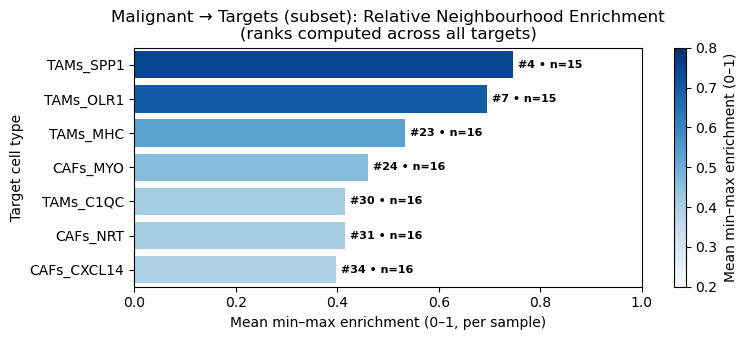

In [17]:
import matplotlib as mpl

# Fixed normalization from 0 to 1
cmap = plt.cm.Blues
norm = mpl.colors.Normalize(vmin=0.2, vmax=0.8)
colors = [cmap(norm(v)) for v in agg_plot["mean_score"]]

# Create figure & axis
fig, ax = plt.subplots(figsize=(8, max(3.5, 0.5*len(agg_plot))))
sns.barplot(data=agg_plot, y="cluster_2", x="mean_score",
            order=agg_plot["cluster_2"], color=None, ax=ax)

# Apply gradient colors
bars = ax.patches
for bar, c in zip(bars, colors):
    bar.set_facecolor(c)
    bar.set_edgecolor("none")  # remove edges

# Annotate
for y, (m, r, n) in enumerate(zip(agg_plot["mean_score"], agg_plot["rank"], agg_plot["n_samples"])):
    ax.text(m + 0.01, y, f"#{r} • n={n}",
            va="center", ha="left", fontsize=8, fontweight="bold")
    
ax.set_xlim(0, 1)
ax.set_xlabel("Mean min–max enrichment (0–1, per sample)")
ax.set_ylabel("Target cell type")
ax.set_title("Malignant → Targets (subset): Relative Neighbourhood Enrichment\n(ranks computed across all targets)")
fig.tight_layout()

# Add colorbar
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
fig.colorbar(sm, ax=ax, label="Mean min–max enrichment (0–1)")
save("EDFig6e_PDAC_CAFs_TAM_relative_enrichment.pdf")
plt.show()

### Fig. 4f: most enriched and depleted neighbours of malignant cells (at least 6 samples)

~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


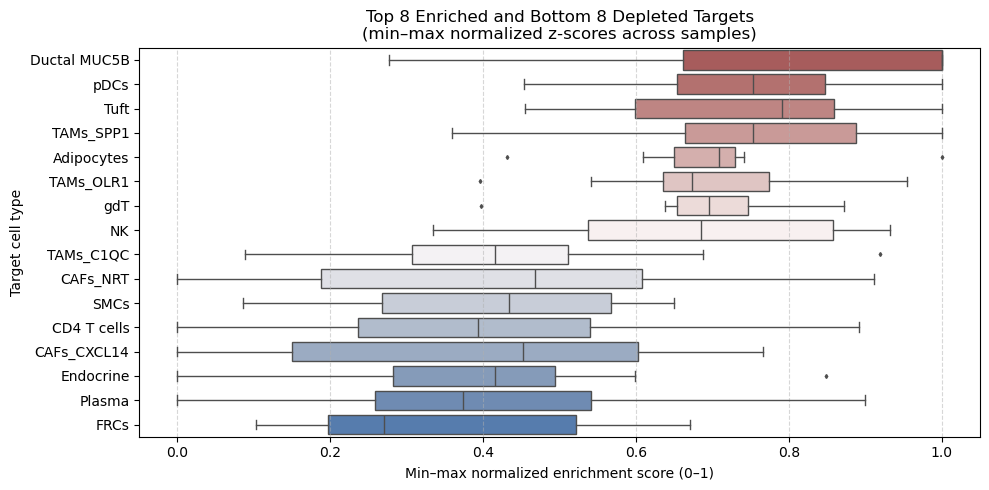

In [18]:
MALIGNANT = "Malignant cells"
min_samples = 6
#highlight_targets = {"CAF_MYO", "TAM_SPP1", "TAM_OLR1"}  # adjust names if needed

def minmax_0to1(x):
    x = x.astype(float)
    rng = x.max() - x.min()
    return (x - x.min()) / rng if rng > 0 else np.zeros_like(x)

# 1) Subset: Malignant → all other types (exclude self/unclassified)
df = z_combined.copy()
df = df[(df["cluster_1"] == MALIGNANT) &
        (df["cluster_2"] != MALIGNANT) &
        (~df["cluster_2"].isin(["Unclassified","Unassigned"]))]

# 2) 0–1 min–max per sample
df["z_minmax01"] = df.groupby("sample")["zscore"].transform(minmax_0to1)

# 3) Aggregate across samples
agg = (df.groupby("cluster_2")
         .agg(mean_score=("z_minmax01","mean"),
              median_score=("z_minmax01","median"),
              n_samples=("sample","nunique"))
         .reset_index())

# Require support across ≥ min_samples
agg = agg[agg["n_samples"] >= min_samples].copy()

# Select top 5 and bottom 5 based on mean_score
top5 = agg.nlargest(8, "mean_score")["cluster_2"]
bottom5 = agg.nsmallest(8, "mean_score")["cluster_2"]
selected = pd.concat([top5, bottom5])

# Filter original df for selected cluster_2 targets
df_selected = df[df["cluster_2"].isin(selected)].copy()

custom_order = [
    "Ductal MUC5B",
    "pDCs",
    "Tuft",
    "TAMs_SPP1",
    "Adipocytes",
    "TAMs_OLR1",
    "gdT",
    "NK",
    "TAMs_C1QC",
    "CAFs_NRT",
    "SMCs",
    "CD4 T cells",
    "CAFs_CXCL14",
    "Endocrine",
    "Plasma",
    "FRCs"
]

df_selected["cluster_2"] = pd.Categorical(
    df_selected["cluster_2"],
    categories=custom_order,
    ordered=True
)

# Plot boxplots
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_selected, x="z_minmax01", y="cluster_2", palette="vlag_r", fliersize=2, linewidth=1)
plt.xlabel("Min–max normalized enrichment score (0–1)")
plt.ylabel("Target cell type")
plt.title("Top 8 Enriched and Bottom 8 Depleted Targets\n(min–max normalized z-scores across samples)")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
save("Fig4f_PDAC_top8_over6sample.pdf")
plt.show()

### Fig. 5d: top neighbours of antigen-presenting and T cell types

In [19]:
# Define target cell types to analyze (CAF subtypes + others)
target_types = ["CAFs_NRT", "TAMs_C1QC", "TAMs_MHC", "CD4 T cells","Migratory DCs", "DC1", "DC2", "CD8 T cells"]
min_samples = 3

# Store results
top_neighbors_by_type = {}

for cell_type in z_combined["cluster_1"].unique():
    if cell_type not in target_types:
        continue

    # Subset for this cell type
    df = z_combined[z_combined["cluster_1"] == cell_type].copy()
    df = df[~df["cluster_2"].isin(["Unassigned", "Unclassified"])]
    df = df[df["cluster_1"] != df["cluster_2"]]

    # Min-max normalize per sample
    df["zscore_minmax"] = df.groupby("sample")["zscore"].transform(
        lambda x: (x - x.min()) / (x.max() - x.min())
    )

    # Compute mean enrichment and sample count per neighbor
    agg = (
        df.groupby("cluster_2")
        .agg(
            mean_score=("zscore_minmax", "mean"),
            n_samples=("sample", "nunique")
        )
        .reset_index()
    )

    # Keep neighbors enriched in ≥ min_samples
    agg = agg[agg["n_samples"] >= min_samples]

    # Select top 5 based on average enrichment
    top5 = agg.sort_values("mean_score", ascending=False).head(5)

    top_neighbors_by_type[cell_type] = top5

In [20]:
# Combine results into a single DataFrame
top_neighbors_df = (
    pd.concat(top_neighbors_by_type, names=["Cell_Type"])
    .reset_index()
    .rename(columns={"cluster_2": "Neighbor", "n_samples": "Samples_enriched_in"})
)

# Optional: sort for readability
top_neighbors_df = top_neighbors_df.sort_values(
    ["Cell_Type", "Samples_enriched_in"],
    ascending=[True, False]
)

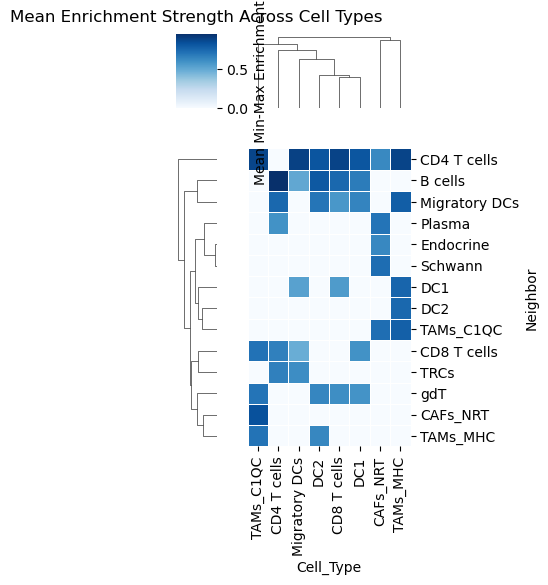

In [21]:
heatmap_scores = top_neighbors_df.pivot(
    index="Neighbor", columns="Cell_Type", values="mean_score"
).fillna(0)

sns.clustermap(
    heatmap_scores,
    cmap="Blues",
    linewidths=0.5,
    linecolor="white",
    row_cluster=True,
    col_cluster=True,
    figsize=(4, 6),
    cbar_kws={"label": "Mean Min-Max Enrichment Score"}
)
plt.title("Mean Enrichment Strength Across Cell Types", y=1.05)
plt.tight_layout()
save("Fig5d_NRT_C1QC_nhood_50.pdf")
plt.show()

## 3. Neighbour composition

For each cell of a given type, the fraction of each other cell type within 50 µm, averaged over the cells of that type in each sample.

In [22]:
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from collections import Counter

def analyze_neighbors_avg_per_cell_malignant(
    adata,
    radius=50,
    label_key="cell_class_threshold",
    spatial_key="spatial",
    center_label="Malignant cells",
    exclude_labels=["Unclassified", "Unassigned"]
):
    """
    Analyze neighborhood composition around each malignant cell,
    averaging over all malignant cells in the sample.

    Parameters:
    -----------
    adata : AnnData
        Annotated data matrix with spatial coordinates and cell type labels.
    radius : float
        Radius (in micrometers) to define the neighborhood.
    label_key : str
        Key in adata.obs for cell type labels.
    spatial_key : str
        Key in adata.obsm for spatial coordinates.
    center_label : str
        Cell type to use as center (typically "Malignant").
    exclude_labels : list of str
        Cell types to exclude from neighbor composition.

    Returns:
    --------
    pd.Series
        Average neighborhood composition per malignant cell (as fractions).
    """
    coords = adata.obsm[spatial_key]
    labels = adata.obs[label_key]
    tree = cKDTree(coords)

    indices = np.where(labels == center_label)[0]
    per_cell_compositions = []

    for idx in indices:
        center = coords[idx]
        nearby_idx = tree.query_ball_point(center, r=radius)

        # Exclude self label and other unwanted categories
        neighbor_labels = [
            t for t in labels.iloc[nearby_idx]
            if t not in exclude_labels and t != center_label
        ]

        if neighbor_labels:
            counts = Counter(neighbor_labels)
            total = sum(counts.values())
            composition = {k: v / total for k, v in counts.items()}
            per_cell_compositions.append(composition)

    if not per_cell_compositions:
        return pd.Series(dtype=float)

    avg_df = pd.DataFrame(per_cell_compositions).fillna(0)
    return avg_df.mean()

In [23]:
def composition_by_sample(center_label):
    results_by_sample = {}
    for adata, sample_name in zip(adata_list, sample_names):
        results_by_sample[sample_name] = analyze_neighbors_avg_per_cell_malignant(
            adata=adata,
            center_label=center_label,
            radius=radius,
            label_key="cell_class_threshold",
            spatial_key="spatial"
        )
    return results_by_sample


def plot_composition(results_by_sample, center_label, name):
    # 1) Stack to samples x neighbors
    # results_by_sample: {'MH065_314': Series(...), 'MH074_314': Series(...), ...}
    wide = pd.DataFrame(results_by_sample).T  # rows = samples, cols = neighbors (fractions)
    wide = wide.fillna(0)

    # If your Series had suffixes like "..._mean", strip them (optional guard)
    if any(col.endswith("_mean") for col in wide.columns):
        wide = wide[[c for c in wide.columns if c.endswith("_mean")]].copy()
        wide.columns = [c[:-5] for c in wide.columns]  # remove "_mean"

    # Drop unwanted labels if present
    wide = wide.drop(columns=[c for c in ["Unclassified", "Unassigned"] if c in wide.columns], errors="ignore")

    # Convert to percentages (optional; remove if you want 0–1 fractions)
    wide_pct = wide * 100

    # 2) Rank neighbors by median across samples
    med_across_samples = wide_pct.median(axis=0).sort_values(ascending=False)

    # Keep top 12 (or fewer if not enough columns)
    topk = med_across_samples.head(min(12, len(med_across_samples))).index.tolist()

    # 3) Long format for plotting (only topk neighbors)
    long = (
        wide_pct[topk]
        .reset_index()
        .rename(columns={"index": "sample"})
        .melt(id_vars="sample", var_name="neighbor", value_name="percent")
    )

    # Order neighbors by their cross-sample median
    order = med_across_samples.loc[topk].index.tolist()

    # 4) Boxplot (variation across samples) + jittered points
    plt.figure(figsize=(7, 4))
    sns.boxplot(
        data=long, x="percent", y="neighbor",
        palette=manual_colors,
        order=order, fliersize=2, linewidth=1
    )
    sns.stripplot(
        data=long, x="percent", y="neighbor",
        order=order, color=".25", size=3, jitter=True, alpha=0.6
    )
    plt.xlabel("Neighbour composition within 50 µm (%)")
    plt.ylabel("Neighbour cell type")
    plt.title(f"{center_label} — Top 12 neighbours by cross-sample median (per-sample distributions)")
    plt.grid(axis="x", linestyle="--", alpha=0.35)
    plt.tight_layout()
    save(name)
    plt.show()
    wide.to_csv(os.path.join(OUTPUT_DIR, name.replace(".pdf", ".tsv")), sep="\t")

### Fig. 4c: around malignant cells

~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


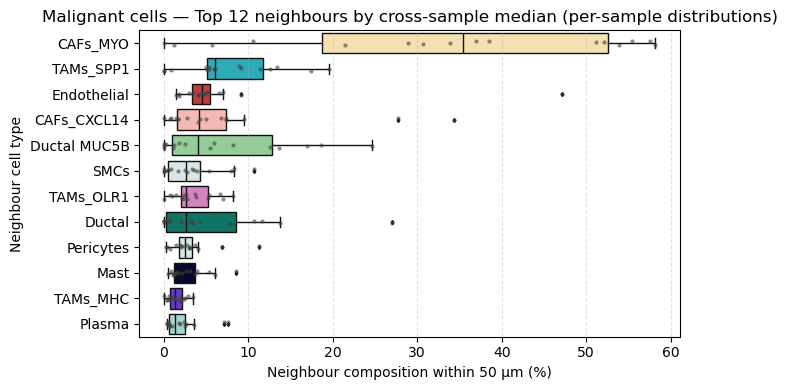

MH065_314     6582
MH074_314    33220
MH096_314      170
MH097_314    14366
MH099_314    91807
MH104_314    12550
MH106_314    28110
MH107_314    20771
MH065_480    17279
MH074_480     3719
MH096_480    21536
MH097_480    34013
MH099_480    61377
MH104_480    30309
MH106_480    20629
MH107_480    48529
Total Malignant cells across all samples: 444967


In [24]:
results_by_sample = composition_by_sample("Malignant cells")
plot_composition(results_by_sample, "Malignant cells", "Fig4c_Malignant_cells_cross_sample_median.pdf")

counts_summary = pd.Series(
    {s: int((ad.obs["cell_class_threshold"] == "Malignant cells").sum()) for s, ad in adata_dict.items()},
    name="malignant_cells",
)
print(counts_summary.to_string())
print(f"Total Malignant cells across all samples: {counts_summary.sum()}")

### Fig. 5c: around CAF, TAM and T cell types

~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


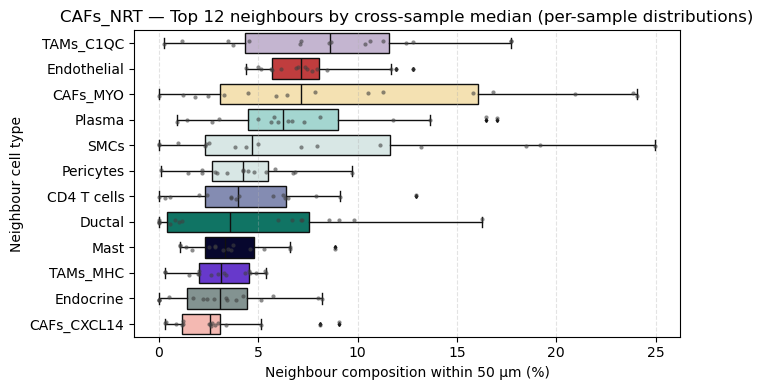

~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


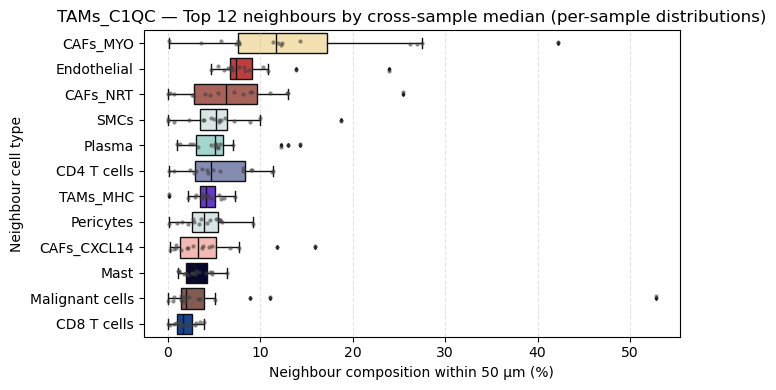

~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


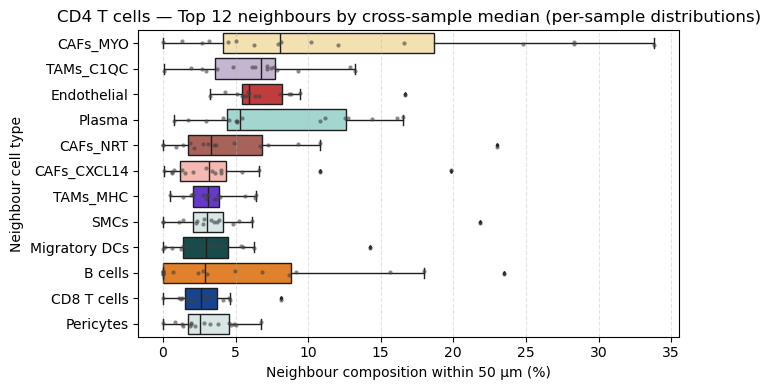

~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


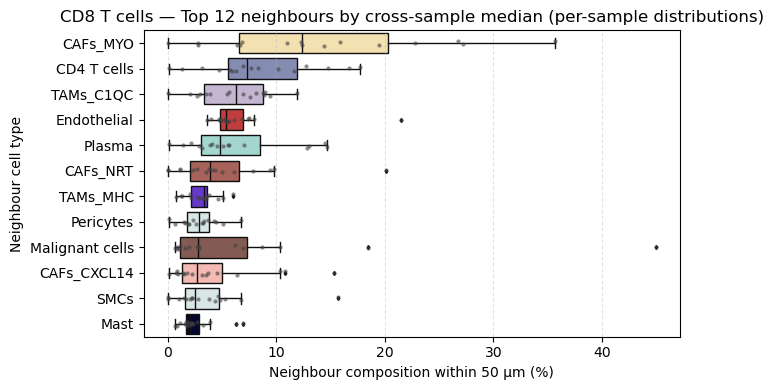

In [25]:
for center_label, name in [
    ("CAFs_NRT", "Fig5c_CAFs_NRT_cross_sample_median.pdf"),
    ("TAMs_C1QC", "Fig5c_TAMs_C1QC_cross_sample_median.pdf"),
    ("CD4 T cells", "Fig5c_CD4_T_cross_sample_median.pdf"),
    ("CD8 T cells", "Fig5c_CD8_T_cross_sample_median.pdf"),
]:
    plot_composition(composition_by_sample(center_label), center_label, name)

## Saved files

In [26]:
print("\n".join(sorted(os.listdir(OUTPUT_DIR))))
print("\n".join(sorted(os.listdir(FIGURE_DIR))))

Fig4c_Malignant_cells_cross_sample_median.tsv
Fig4e_posthoc_paired_ttests.tsv
Fig4e_repeated_measures_anova.tsv
Fig4e_summary.tsv
Fig5c_CAFs_NRT_cross_sample_median.tsv
Fig5c_CD4_T_cross_sample_median.tsv
Fig5c_CD8_T_cross_sample_median.tsv
Fig5c_TAMs_C1QC_cross_sample_median.tsv
Min-distance_Profiling50micrometers_Malignantcells.csv.gz
Nhood_Enrichment_50micron_all.csv.gz
figures
EDFig6d_Persample_median_distant_PDAC_neighbours_all.pdf
EDFig6e_PDAC_CAFs_TAM_relative_enrichment.pdf
Fig4c_Malignant_cells_cross_sample_median.pdf
Fig4e_Persample_median_distant_PDAC_neighbours_TAMs_CAFs.pdf
Fig4f_PDAC_top8_over6sample.pdf
Fig5c_CAFs_NRT_cross_sample_median.pdf
Fig5c_CD4_T_cross_sample_median.pdf
Fig5c_CD8_T_cross_sample_median.pdf
Fig5c_TAMs_C1QC_cross_sample_median.pdf
Fig5d_NRT_C1QC_nhood_50.pdf
